## Data visualization

False


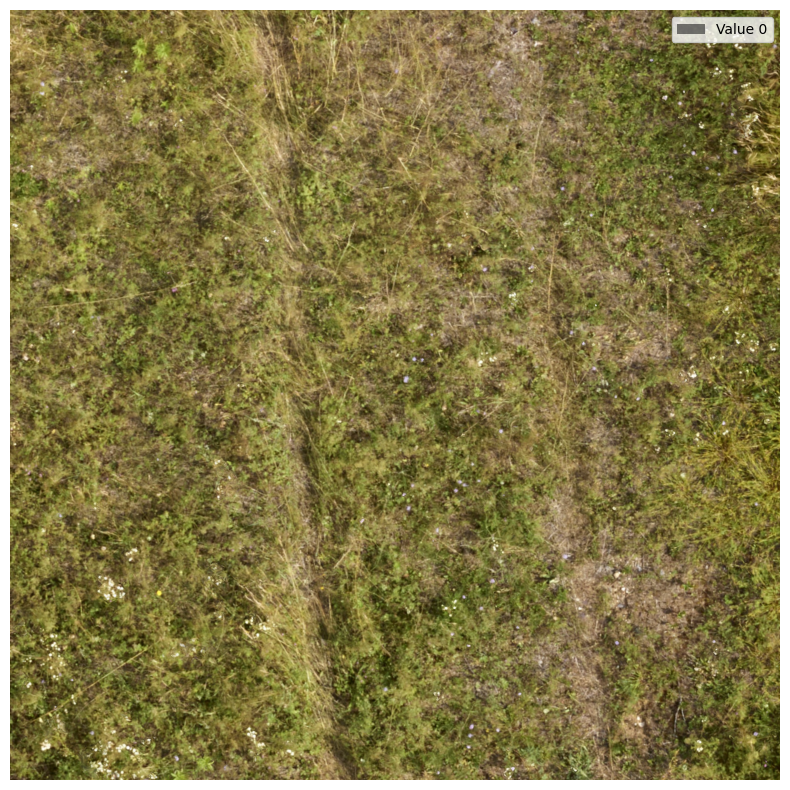

In [6]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from osgeo import gdal

base_path = "/zfs/ai4good/datasets/Neophytes/2025/Rivera_1_1"

image_path = Path(f"{base_path}/train/images") / random.choice(os.listdir(f"{base_path}/train/images"))

def mask_filename(image_path):
    parts = image_path.stem.split("_")
    mask_stem = "_".join(parts[:-2] + ["mask"] + parts[-2:])
    return image_path.with_name(mask_stem + image_path.suffix)

image_ds = gdal.Open(str(image_path))
mask_path = Path(f"{base_path}/train/masks") / mask_filename(image_path).name
mask_ds = gdal.Open(str(mask_path))

image = image_ds.ReadAsArray()
mask = mask_ds.ReadAsArray()

if image.ndim == 3:
    image = np.moveaxis(image, 0, -1)

rgb = image[..., :3]

if mask.ndim == 3:
    mask = mask[0]
print(np.any(np.dstack(mask) != 0))


num_classes = int(mask.max()) + 1
colors = plt.colormaps["tab10"].resampled(max(num_classes, 1))(range(max(num_classes, 1)))
colors[0] = (0, 0, 0, 0) 
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, num_classes + 0.5), cmap.N)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(rgb)
ax.imshow(mask, cmap=cmap, norm=norm, alpha=0.5, interpolation="nearest")

values = np.unique(mask)
handles = [
    Patch(
        facecolor=cmap(norm(value)),
        alpha=0.5,
        label=f"Value {value}"
    )
    for value in values
]

ax.legend(handles=handles, loc="upper right")
ax.axis("off")
plt.show()
